In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import joblib

sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'serif' 
plt.rcParams['figure.dpi'] = 300      

In [ ]:
# =========================================================
# PART 1: TABLE 1 - DATASET DEMOGRAPHICS
# =========================================================
print("Generating Table 1: Dataset Statistics...")
df = pd.read_csv('../data/clean_data.csv')

# Select key variables for the summary table
key_vars = ['annual_income', 'debt_to_income', 'loan_amount', 'interest_rate', 'total_credit_limit']
labels = ['Annual Income ($)', 'Debt-to-Income Ratio', 'Loan Amount ($)', 'Interest Rate (%)', 'Total Credit Limit ($)']

# Calculate stats
summary_table = df[key_vars].describe().T[['mean', 'std', 'min', '50%', 'max']]
summary_table.columns = ['Mean', 'Std Dev', 'Min', 'Median', 'Max']
summary_table.index = labels

# Save as CSV 
summary_table.to_csv('../data/table1_demographics.csv')
print(summary_table)
print("\nSaved to 'table1_demographics.csv'")

Generating Table 1: Dataset Statistics...
                                 Mean        Std Dev      Min     Median  \
Annual Income ($)        79412.738885   64695.239538  3000.00   65000.00   
Debt-to-Income Ratio        19.308192      15.004851     0.00      17.57   
Loan Amount ($)          16357.528067   10301.614193  1000.00   14500.00   
Interest Rate (%)           12.422459       4.997904     5.31      11.98   
Total Credit Limit ($)  183749.168905  187729.694292     0.00  114766.00   

                               Max  
Annual Income ($)       2300000.00  
Debt-to-Income Ratio        469.09  
Loan Amount ($)           40000.00  
Interest Rate (%)            30.94  
Total Credit Limit ($)  3386034.00  

Saved to 'table1_demographics.csv'



Generating Model Comparison Plot...


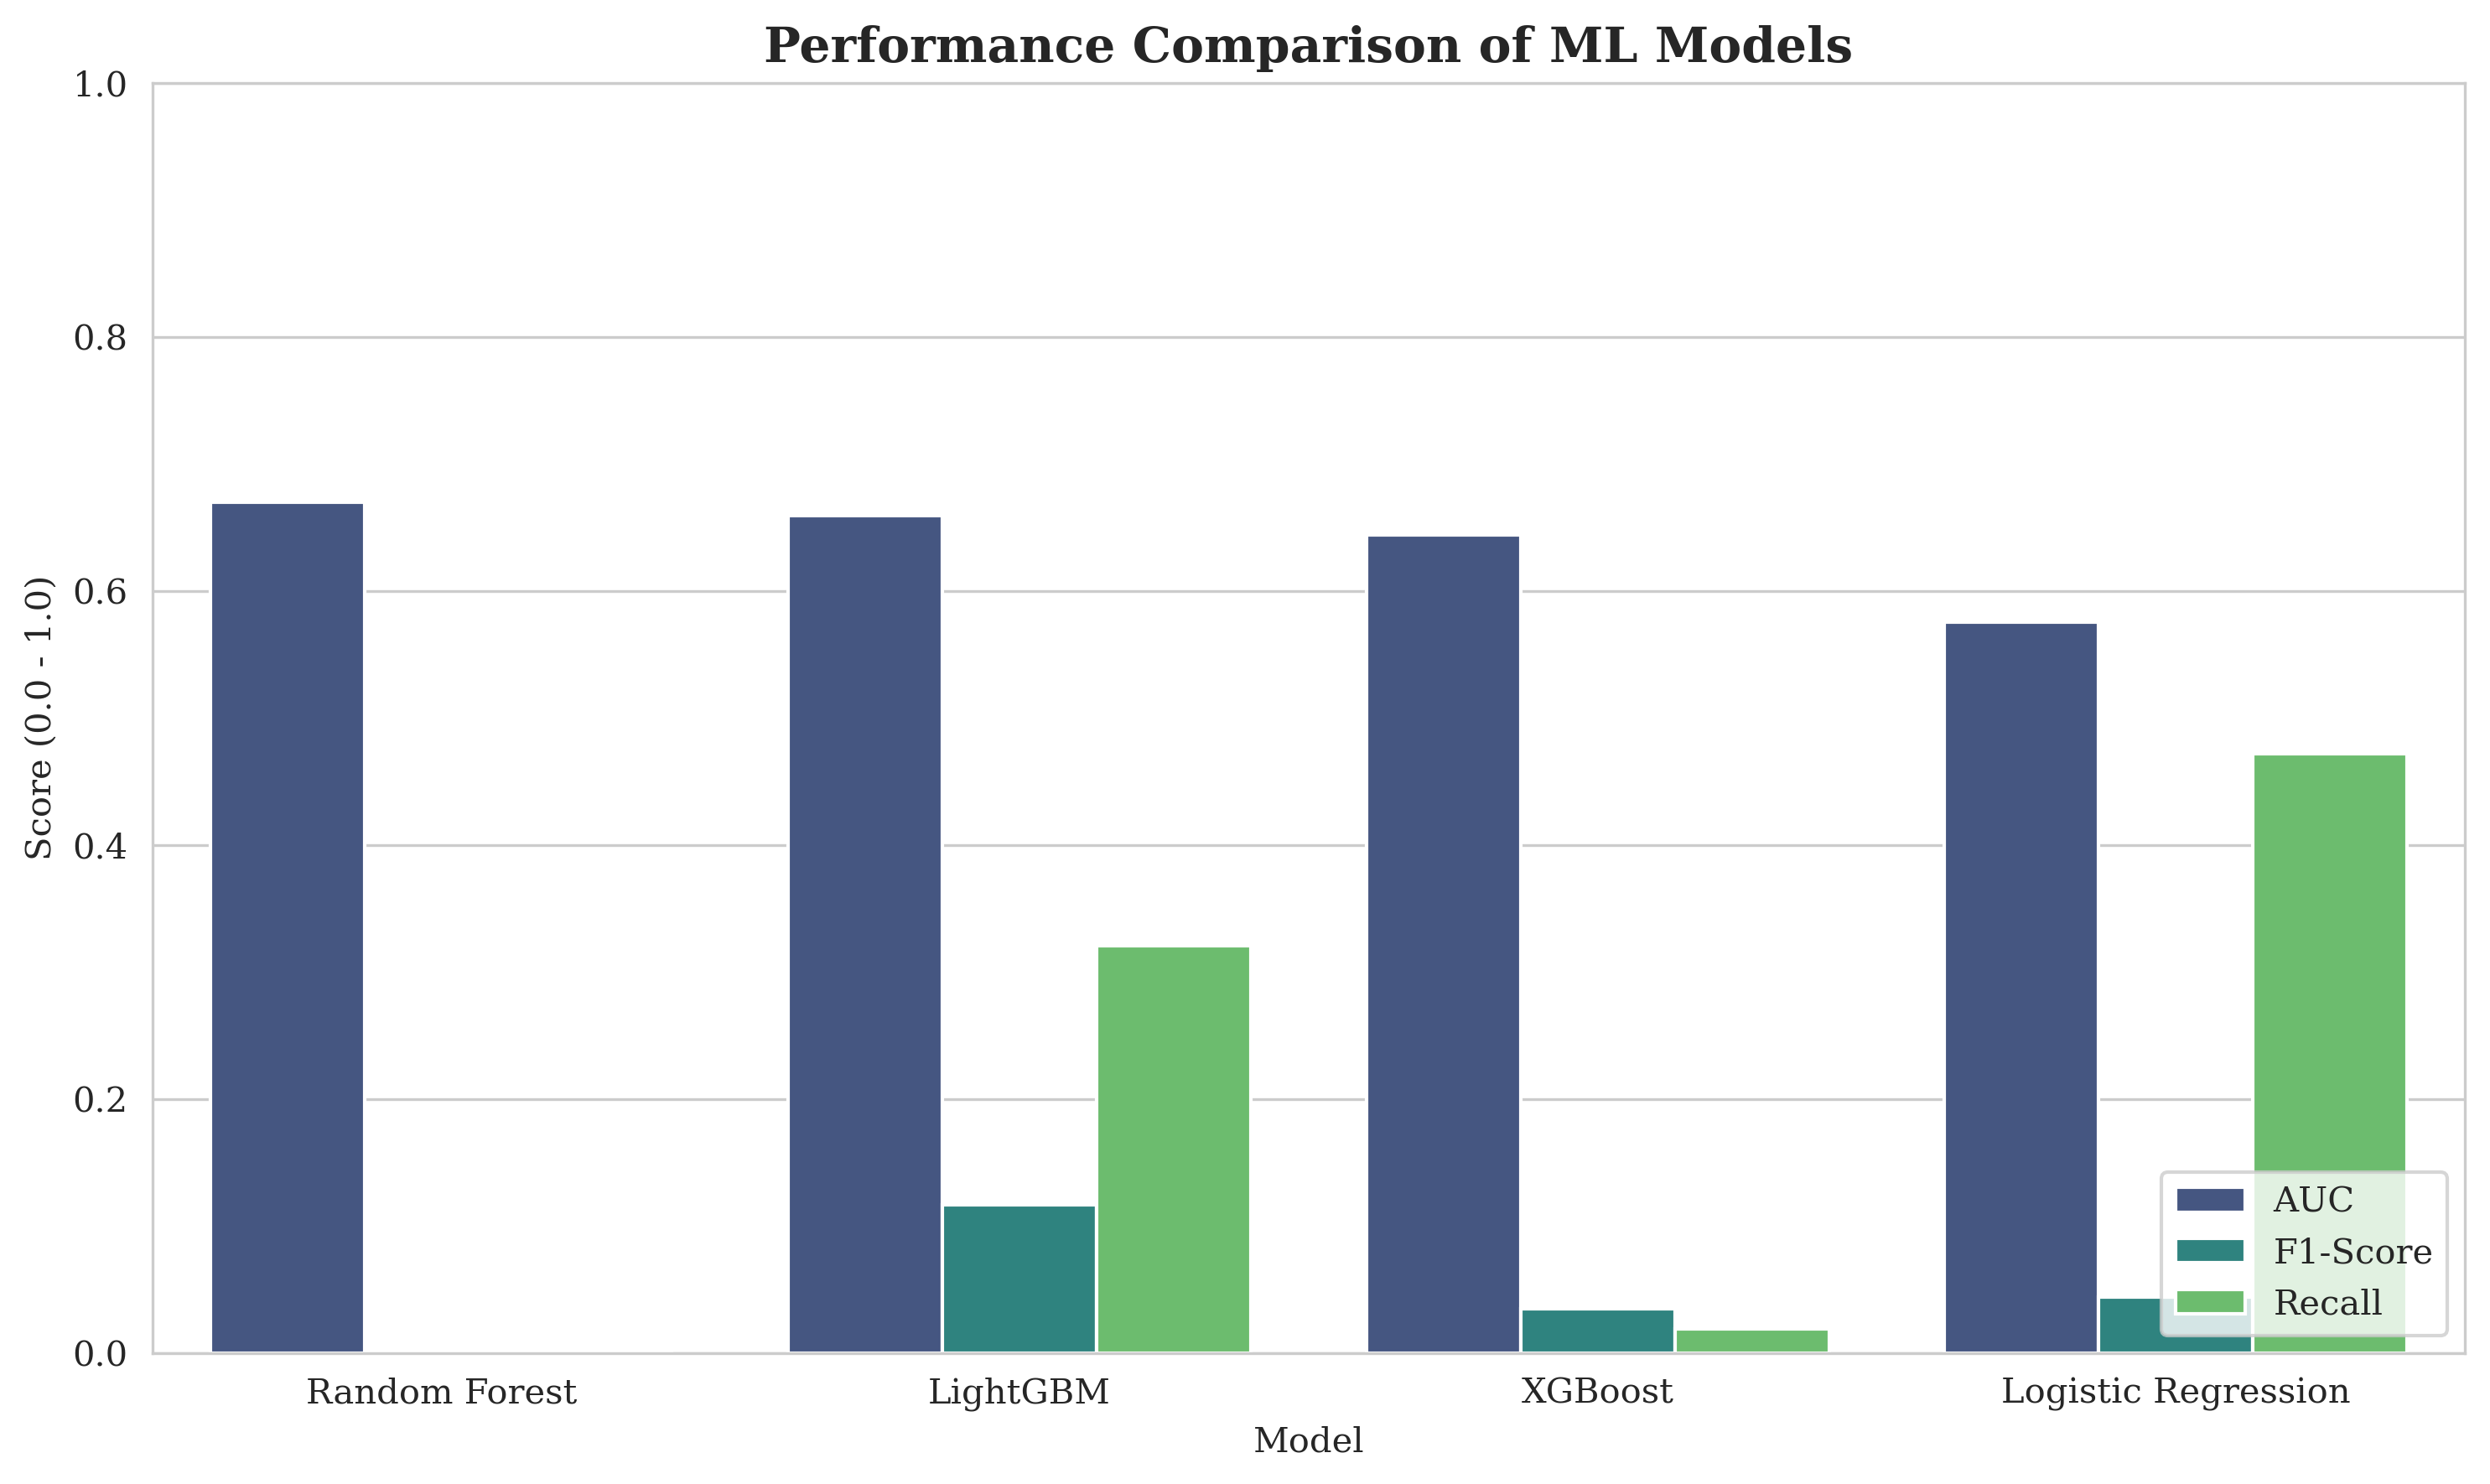

Saved to 'final_figure_model_comparison.png'


In [ ]:
# =========================================================
# PART 2: FIGURE - MODEL COMPARISON BAR CHART
# =========================================================
print("\nGenerating Model Comparison Plot...")
from sklearn.metrics import recall_score, f1_score
from lightgbm import LGBMClassifier

try:
    results = pd.read_csv('../data/model_results.csv')
    
    # 1. Load data to dynamically calculate LightGBM's optimized metrics
    X_train_res = pd.read_csv('../data/X_train_resampled.csv')
    y_train_res = pd.read_csv('../data/y_train_resampled.csv').values.ravel()
    X_test_plot = pd.read_csv('../data/X_test.csv')
    y_test_plot = pd.read_csv('../data/y_test.csv').values.ravel()
    
    # 2. Retrain LightGBM
    lgbm_model = LGBMClassifier(random_state=42, verbose=-1)
    lgbm_model.fit(X_train_res, y_train_res)
    
    # 3. Predict using the optimized threshold
    optimal_threshold = 0.0344
    y_proba = lgbm_model.predict_proba(X_test_plot)[:, 1]
    y_pred_opt = (y_proba >= optimal_threshold).astype(int)
    
    # 4. Calculate metrics dynamically (No magic numbers!)
    dynamic_recall = recall_score(y_test_plot, y_pred_opt)
    dynamic_f1 = f1_score(y_test_plot, y_pred_opt)
    
    # 5. Safely update the results dataframe
    results.loc[results['Model'] == 'LightGBM', 'Recall'] = dynamic_recall
    results.loc[results['Model'] == 'LightGBM', 'F1-Score'] = dynamic_f1
    
    # Reshape for plotting (Melt)
    results_melted = results.melt(id_vars="Model", value_vars=["AUC", "F1-Score", "Recall"], 
                                  var_name="Metric", value_name="Score")

    plt.figure(figsize=(10, 6))
    sns.barplot(x="Model", y="Score", hue="Metric", data=results_melted, palette="viridis")
    plt.title("Performance Comparison of ML Models", fontsize=14, fontweight='bold')
    plt.ylabel("Score (0.0 - 1.0)")
    plt.ylim(0, 1.0)
    plt.legend(loc='lower right', frameon=True)
    plt.tight_layout()
    plt.savefig('../plots/final_figure_model_comparison.png')
    plt.show()
    print("Saved to '../plots/final_figure_model_comparison.png'")
    
except FileNotFoundError:
    print("WARNING: Data or 'model_results.csv' not found.")


Generating Confusion Matrix for LightGBM...


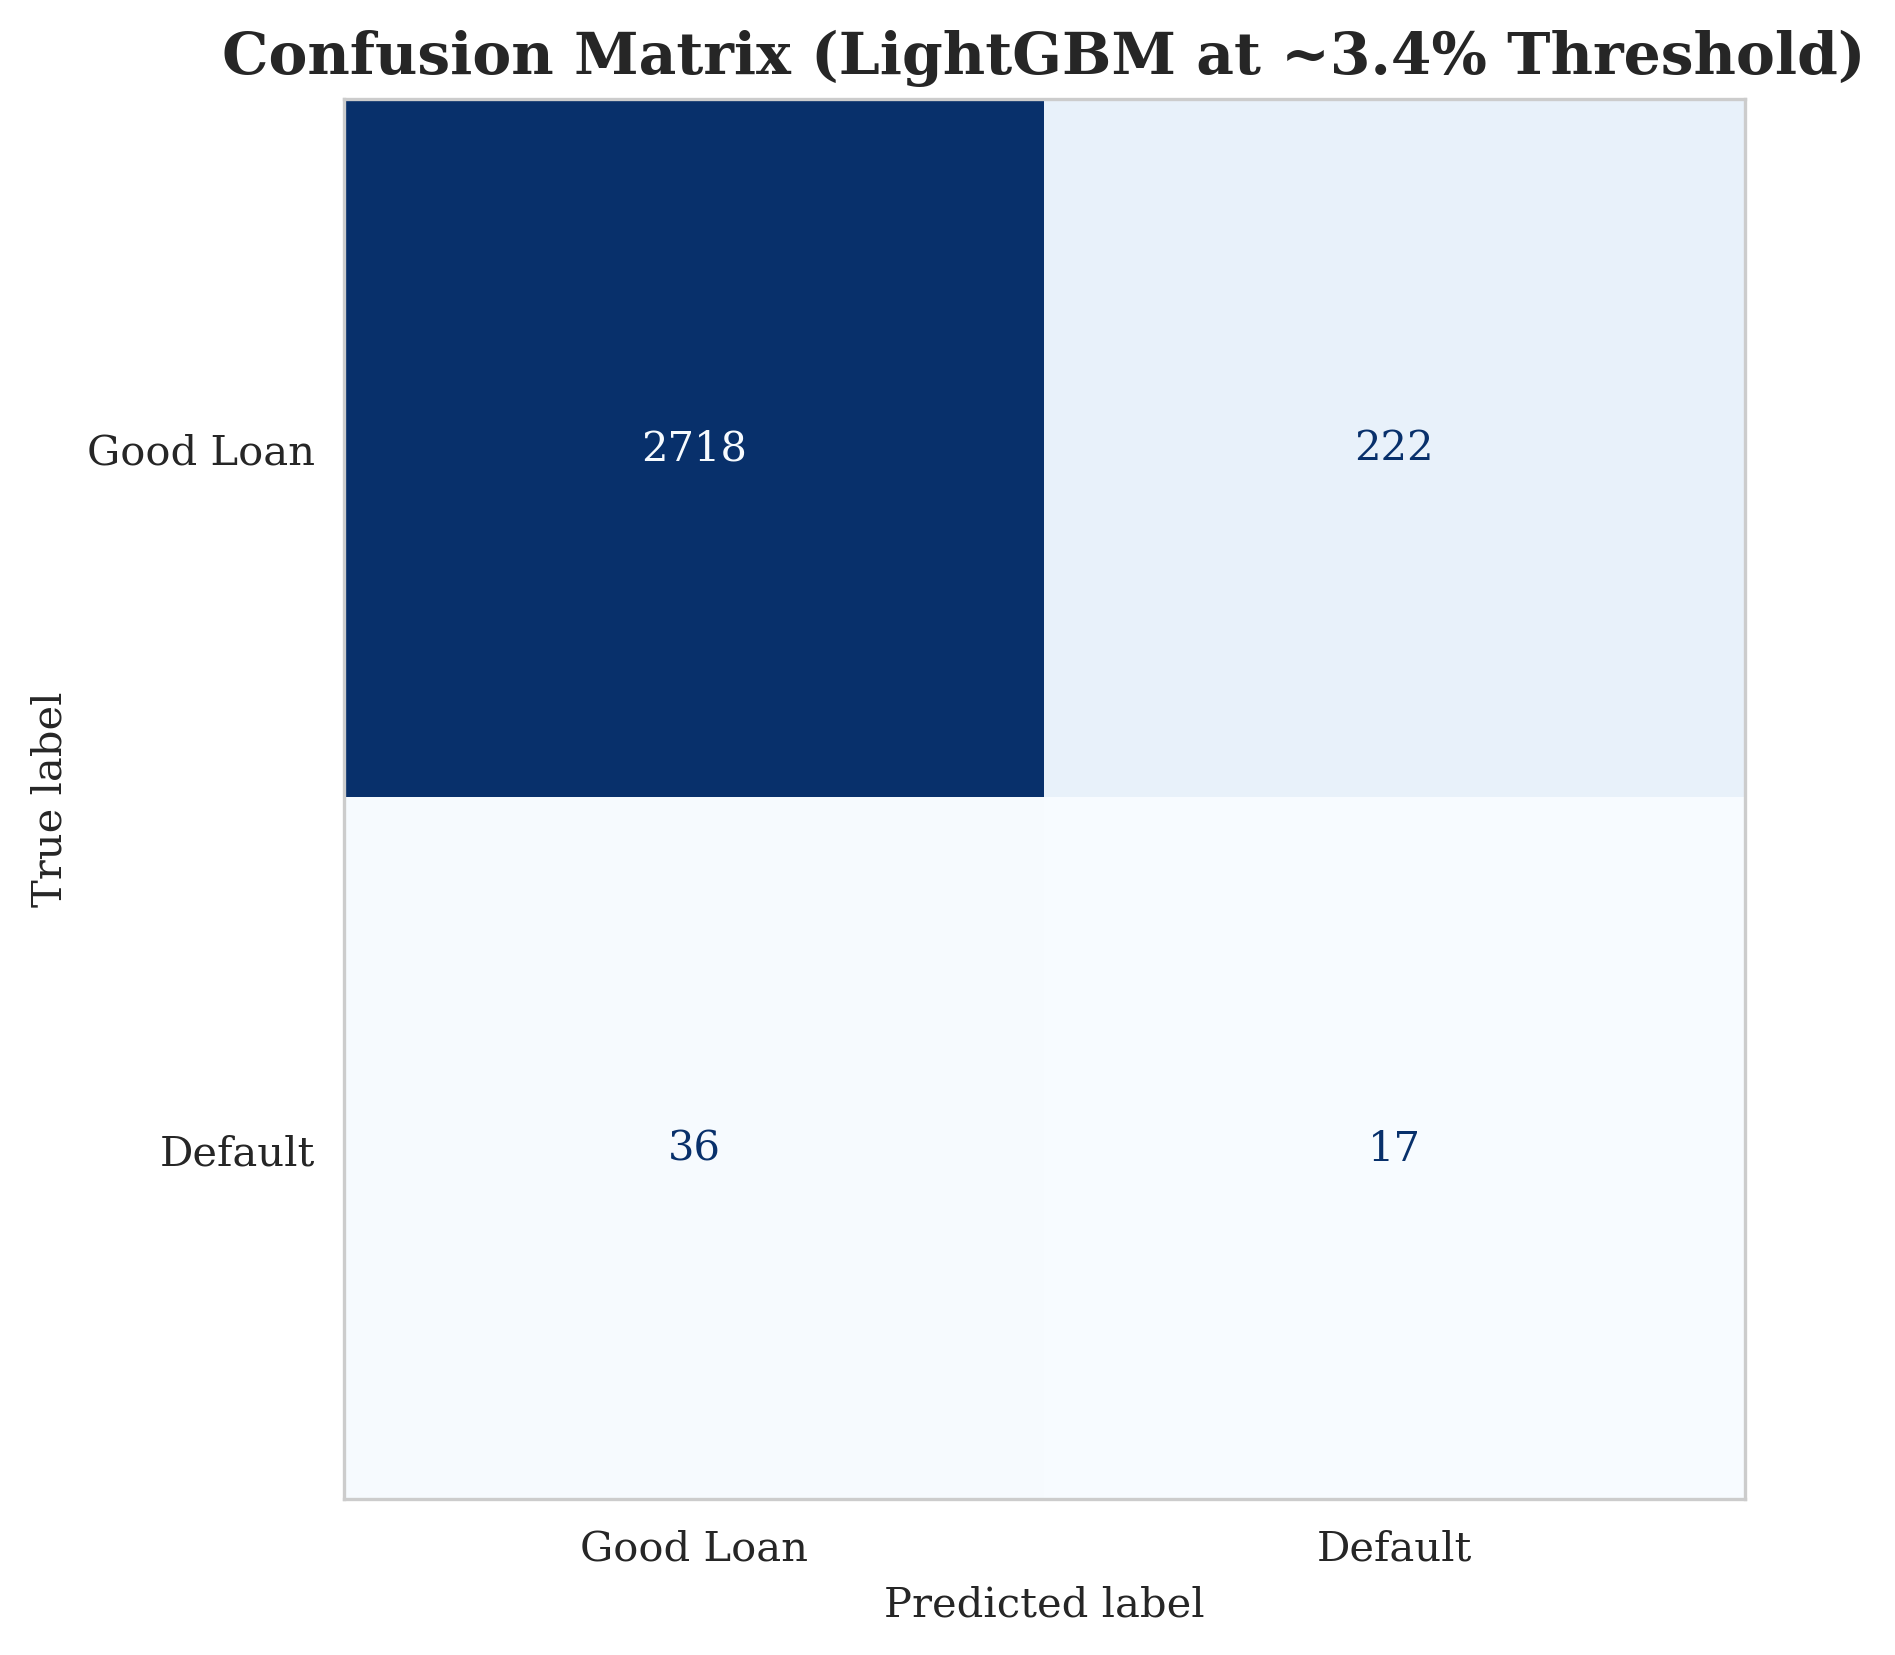

Saved to '../plots/final_figure_confusion_matrix.png'


In [ ]:
# =========================================================
# PART 3: FIGURE - CONFUSION MATRIX (BEST MODEL)
# =========================================================
print("\nGenerating Confusion Matrix for LightGBM...")

# Load Data
X_train = pd.read_csv('../data/X_train_resampled.csv')
y_train = pd.read_csv('../data/y_train_resampled.csv').values.ravel()
X_test = pd.read_csv('../data/X_test.csv')
y_test = pd.read_csv('../data/y_test.csv').values.ravel()

# Retrain LightGBM
model = LGBMClassifier(random_state=42, verbose=-1)
model.fit(X_train, y_train)

# --- Predict using probabilities and the optimized 0.0344 threshold ---
optimal_threshold = 0.0344
y_proba = model.predict_proba(X_test)[:, 1]
y_pred_optimized = (y_proba >= optimal_threshold).astype(int)
# ---------------------------------------------------------------------------

# Plot
cm = confusion_matrix(y_test, y_pred_optimized)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Good Loan', 'Default'])

plt.figure(figsize=(6, 6))
disp.plot(cmap='Blues', values_format='d', ax=plt.gca(), colorbar=False)
plt.title('Confusion Matrix (LightGBM at ~3.4% Threshold)', fontsize=14, fontweight='bold')
plt.grid(False) # Turn off grid for CM clarity
plt.tight_layout()
plt.savefig('../plots/final_figure_confusion_matrix.png')
plt.show()
print("Saved to '../plots/final_figure_confusion_matrix.png'")


Generating Feature Importance Plot...


C:\Users\Yahya\AppData\Local\Temp\ipykernel_10824\3589157547.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='mako')


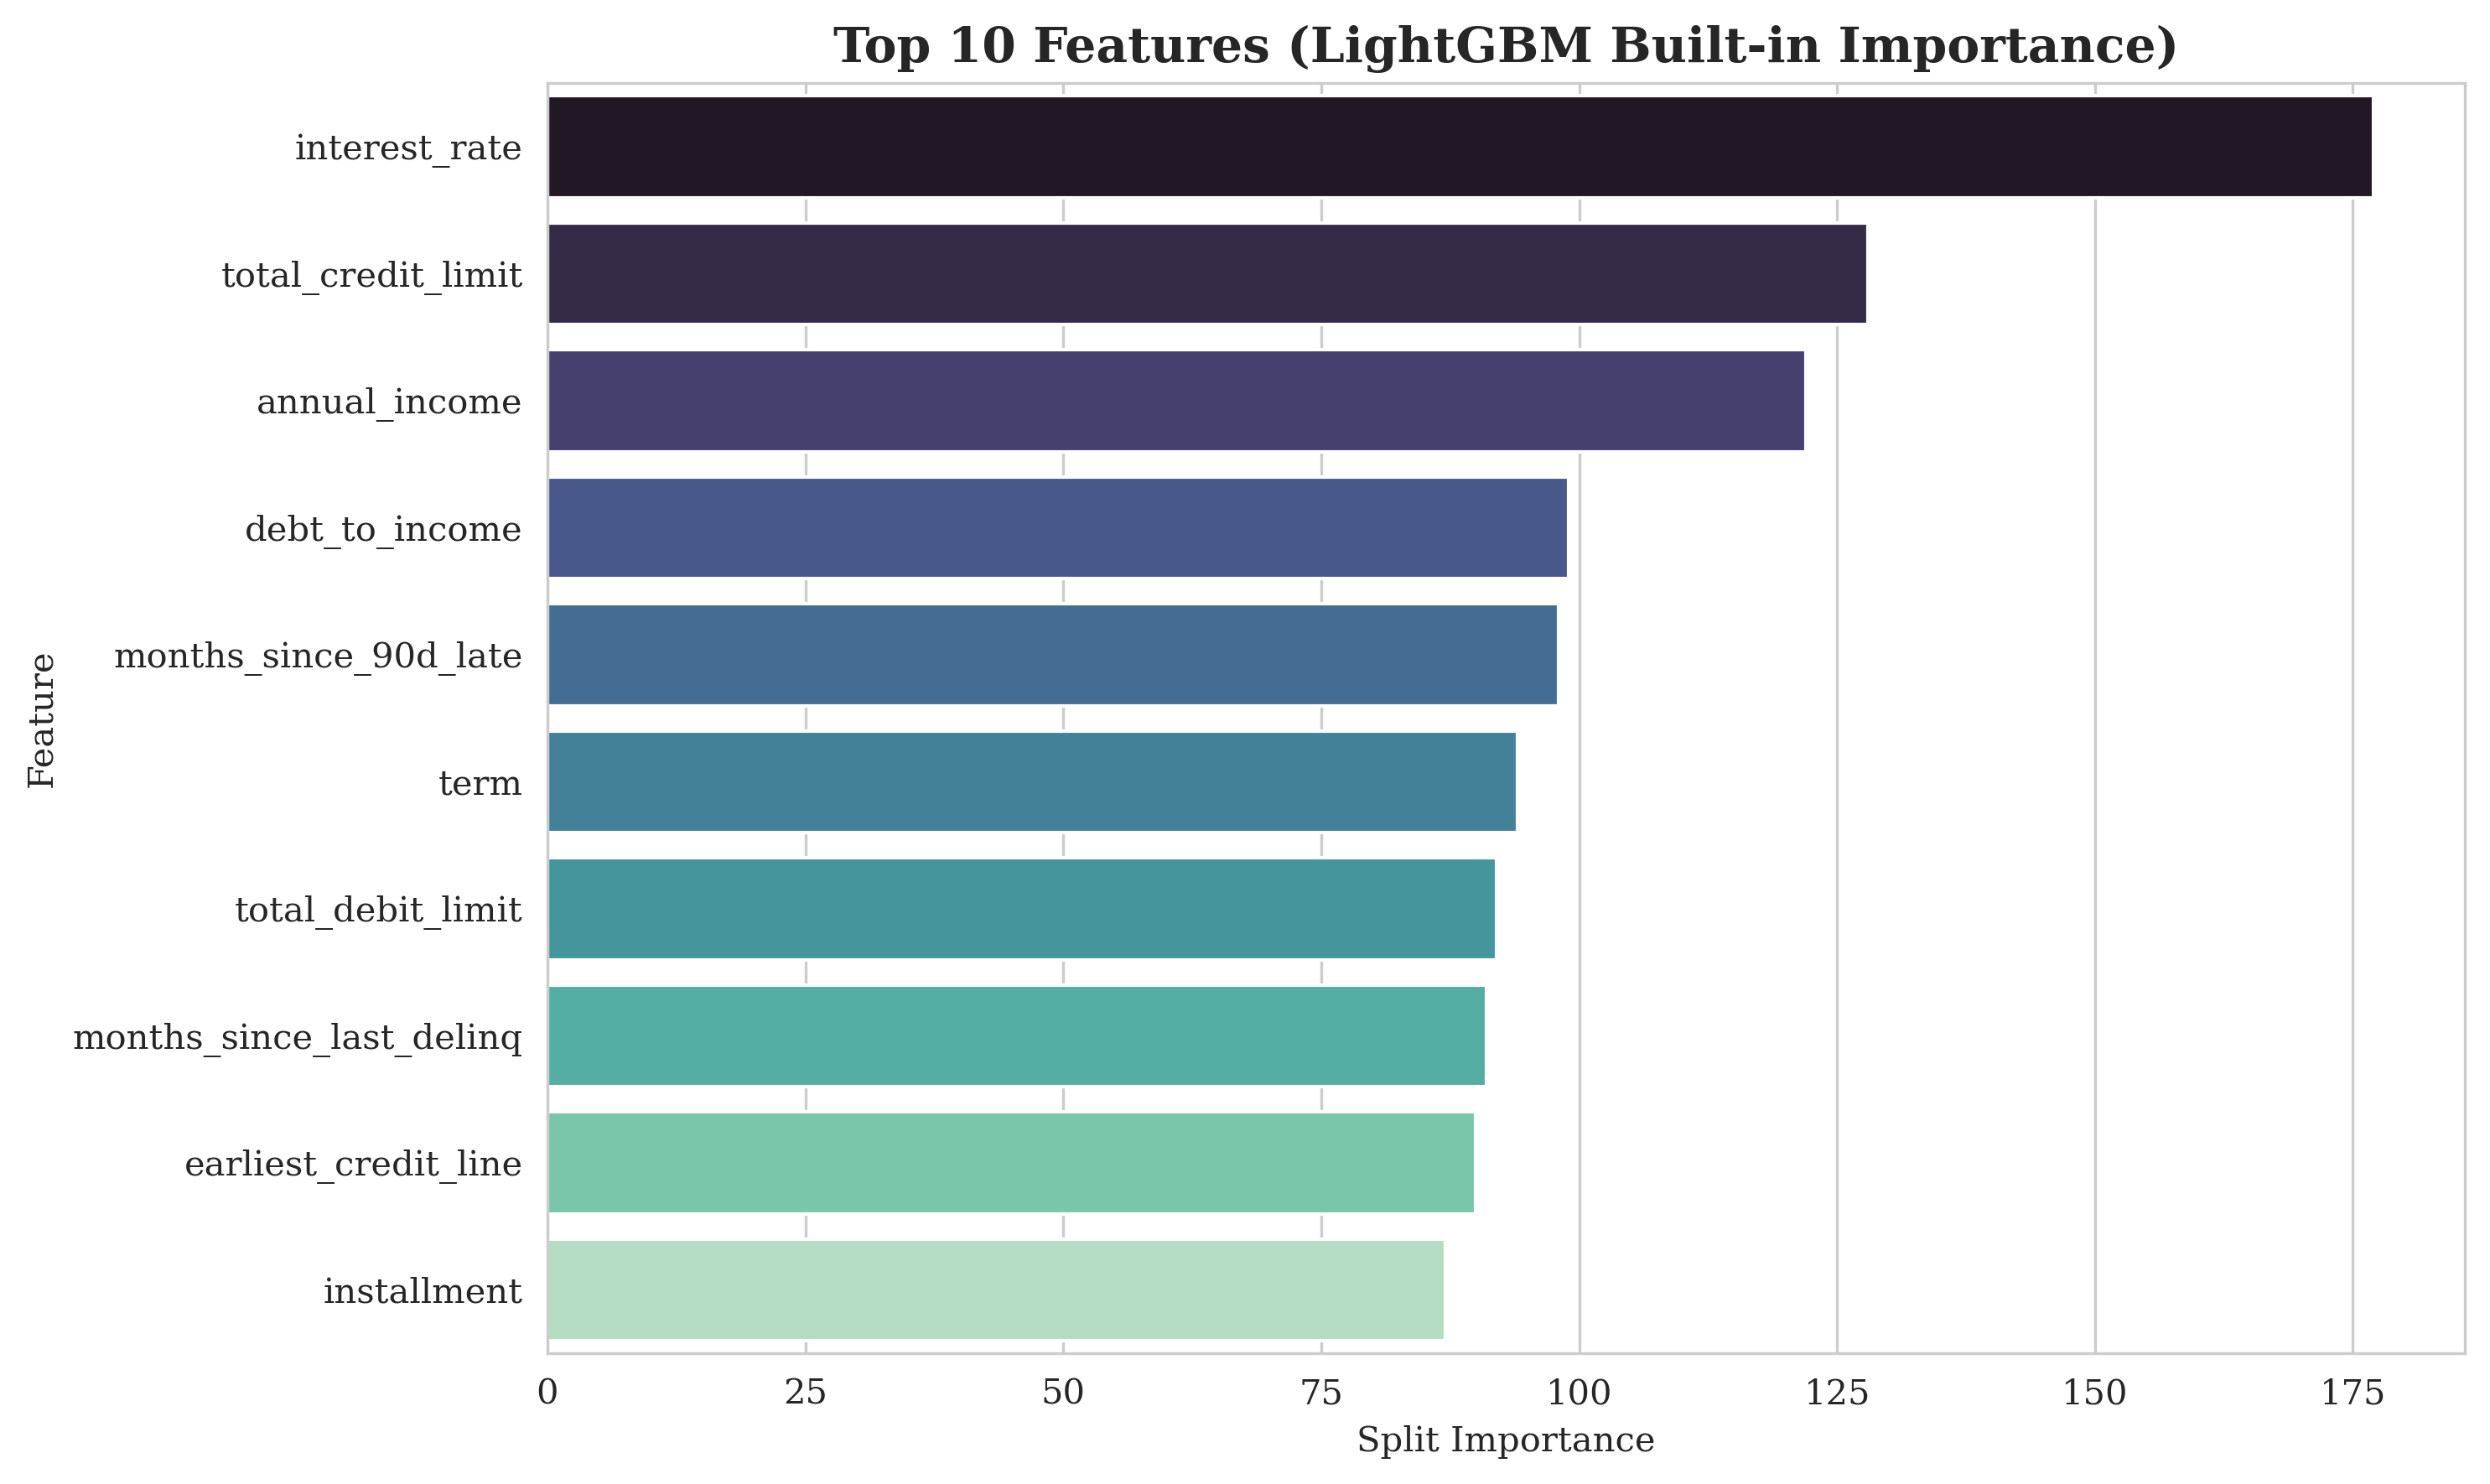

Saved to '../plots/final_figure_feature_importance.png'

DONE! All final visuals generated.


In [5]:
# =========================================================
# PART 4: FIGURE - TRADITIONAL FEATURE IMPORTANCE
# =========================================================
print("\nGenerating Feature Importance Plot...")

# Get importance
importance = model.feature_importances_
feature_names = X_train.columns
feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importance})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='mako')
plt.title('Top 10 Features (LightGBM Built-in Importance)', fontsize=14, fontweight='bold')
plt.xlabel('Split Importance')
plt.tight_layout()
plt.savefig('../plots/final_figure_feature_importance.png')
plt.show()
print("Saved to '../plots/final_figure_feature_importance.png'")

print("\nDONE! All final visuals generated.")